<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A05_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Був присутній на парі.**

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [2]:
# Завантажте датасет з Kaggle
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

100%|██████████| 194k/194k [00:00<00:00, 58.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])
df = pd.read_csv(file_path)
print(f"Розмірність датасету: {df.shape}")
print("\n-- Перші 5 рядків (head) --")
display(df.head())
print("\n-- Інформація про типи даних та пропуски (info) --")
df.info()
print("\n-- Основні статистичні характеристики (describe) --")
display(df.describe())

Розмірність датасету: (3557, 29)

-- Перші 5 рядків (head) --


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



-- Інформація про типи даних та пропуски (info) --
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  cond

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

date_col = [col for col in df.columns if 'date' in col.lower()][0]
df[date_col] = pd.to_datetime(df[date_col])
df = df.sort_values(by=date_col)
cols_to_drop = [col for col in ['Unnamed: 0', 'id', 'index'] if col in df.columns]
if cols_to_drop:
    df = df.drop(columns=cols_to_drop)
df = df.set_index(date_col)
df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
print(f"Форма датасету: {df.shape}")
print(f"Діапазон дат: від {df.index.min().strftime('%Y-%m-%d')} до {df.index.max().strftime('%Y-%m-%d')}")
print("\nІнформація про структуру стовпців та типи даних:")
df.info()

Форма датасету: (3557, 27)
Діапазон дат: від 2013-04-14 до 2024-11-30

Інформація про структуру стовпців та типи даних:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions            

In [6]:
# Перевірте наявність пропущених значень
print("Кількість пропущених значень за стовпцями:")
missing_values = df.isnull().sum()
display(missing_values)
if missing_values.sum() == 0:
    print("\nПропущених значень немає.")
else:
    print(f"\nЗагальна кількість пропусків: {missing_values.sum()}")

Кількість пропущених значень за стовпцями:


,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0



Пропущених значень немає.


Графік температури

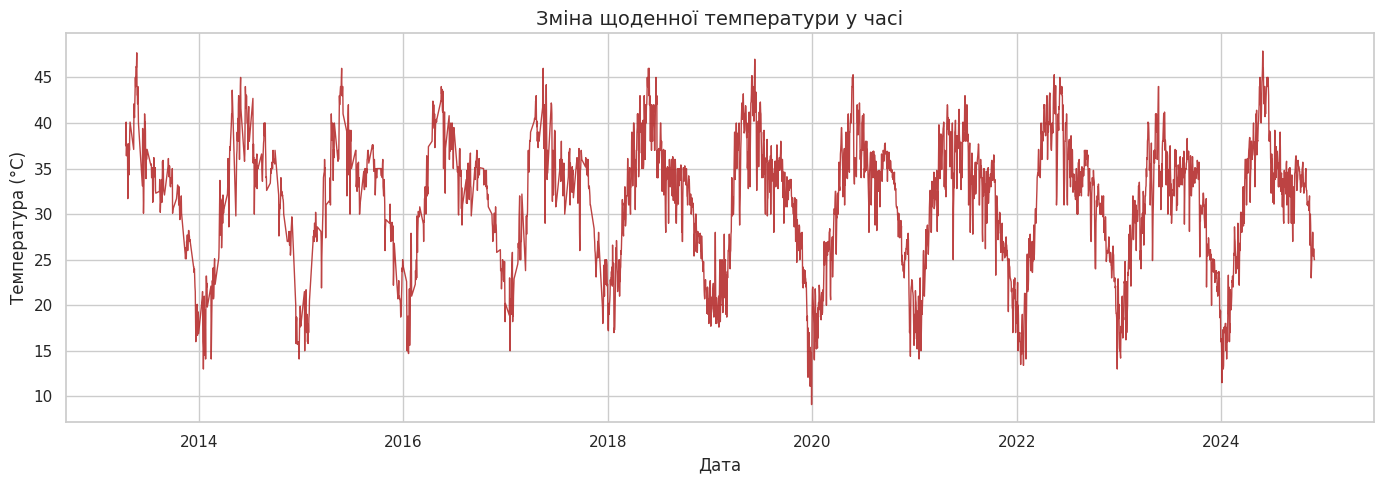

In [7]:
# Побудуйте графік зміни температури у часі
temp_col = [c for c in df.columns if 'temp' in c.lower()][0]
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], color='firebrick', lw=1, alpha=0.85)
plt.title('Зміна щоденної температури у часі', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.tight_layout()
plt.show()

Ковзне середнє

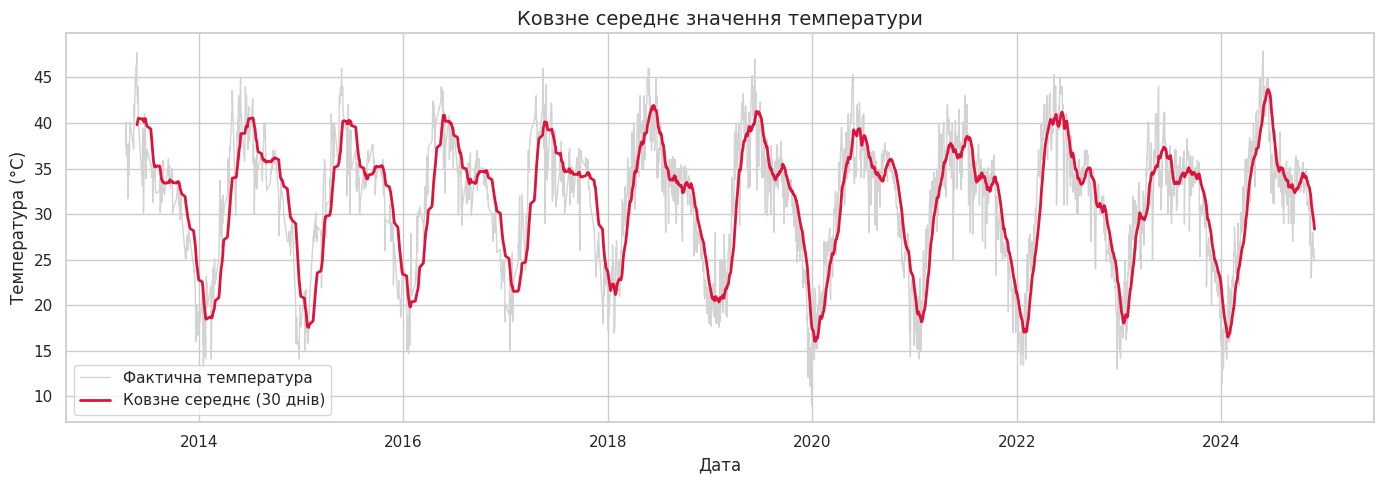

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['temp_ma30'] = df[temp_col].rolling(window=30).mean()
plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], color='lightgray', lw=1, label='Фактична температура')
plt.plot(df.index, df['temp_ma30'], color='crimson', lw=2, label='Ковзне середнє (30 днів)')
plt.title('Ковзне середнє значення температури', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Розподіл температури

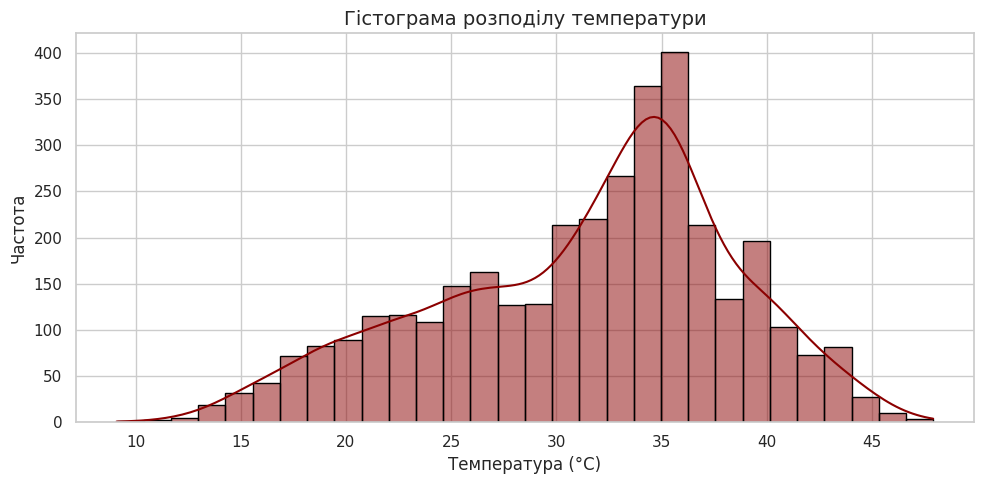

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))
sns.histplot(df[temp_col], kde=True, bins=30, color='darkred', edgecolor='black')
plt.title('Гістограма розподілу температури', fontsize=14)
plt.xlabel('Температура (°C)', fontsize=12)
plt.ylabel('Частота', fontsize=12)
plt.tight_layout()
plt.show()

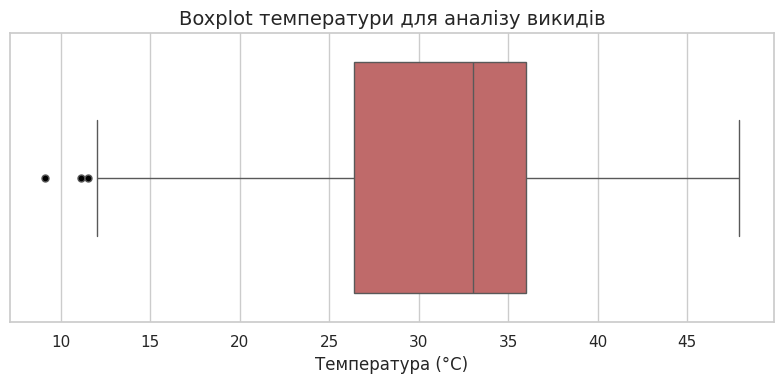

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[temp_col], color='indianred', flierprops={'markerfacecolor': 'black', 'markersize': 5})
plt.title('Boxplot температури для аналізу викидів', fontsize=14)
plt.xlabel('Температура (°C)', fontsize=12)
plt.tight_layout()
plt.show()

Аналіз автокореляції
ACF

PACF

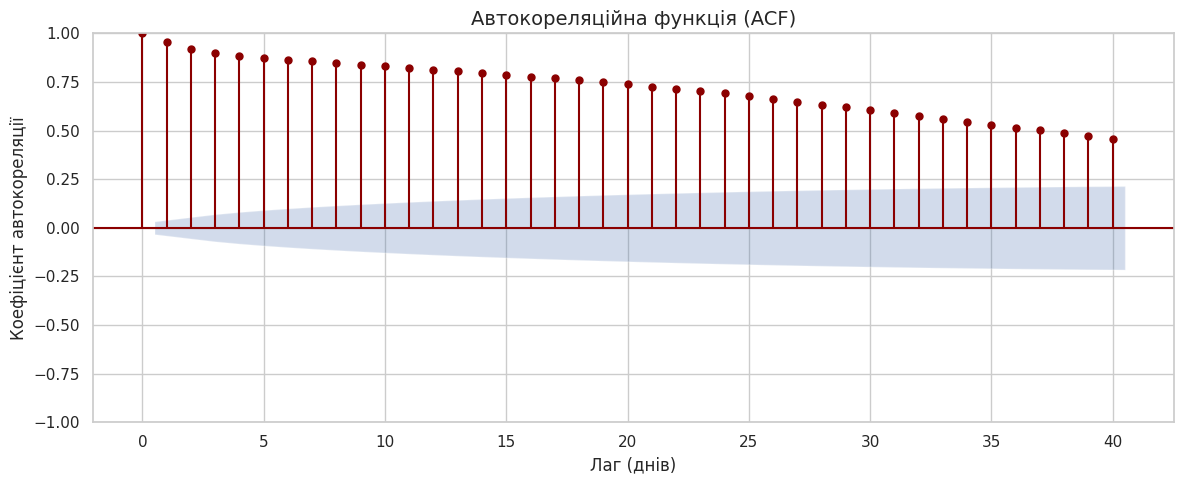

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(12, 5))
plot_acf(df[temp_col].dropna(), lags=40, ax=ax, color='darkred', vlines_kwargs={'colors': 'darkred'})
ax.set_title('Автокореляційна функція (ACF)', fontsize=14)
ax.set_xlabel('Лаг (днів)', fontsize=12)
ax.set_ylabel('Коефіцієнт автокореляції', fontsize=12)
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

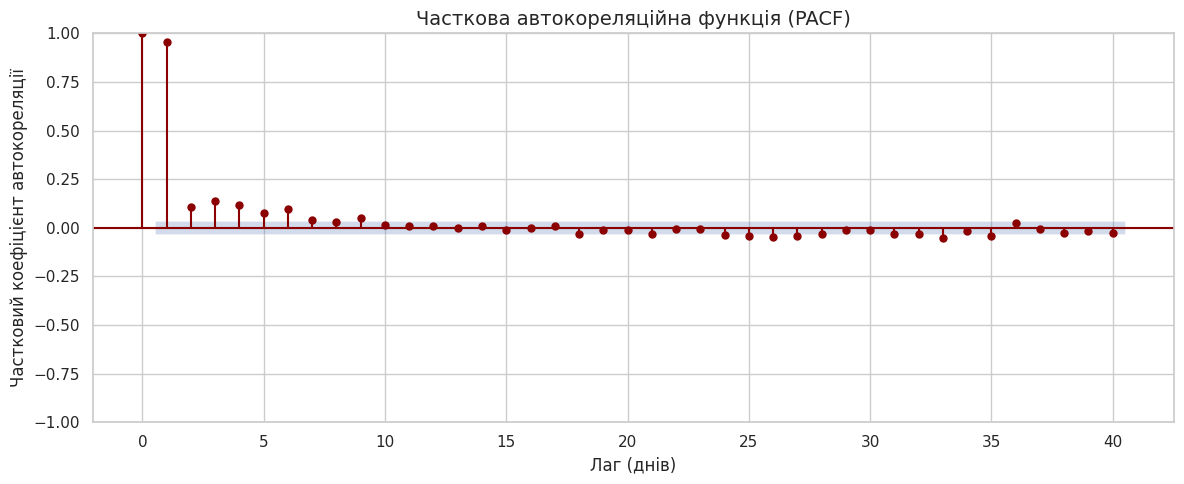

In [14]:
# Побудуйте графік часткової автокореляційної функції (PACF)
from statsmodels.graphics.tsaplots import plot_pacf
fig, ax = plt.subplots(figsize=(12, 5))
plot_pacf(df[temp_col].dropna(), lags=40, ax=ax, method='yw', color='darkred', vlines_kwargs={'colors': 'darkred'})
ax.set_title('Часткова автокореляційна функція (PACF)', fontsize=14)
ax.set_xlabel('Лаг (днів)', fontsize=12)
ax.set_ylabel('Частковий коефіцієнт автокореляції', fontsize=12)
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

Train період: 2013-04-14 — 2022-12-19 (2845 спостережень)
Test період:  2022-12-20 — 2024-11-30 (712 спостережень)


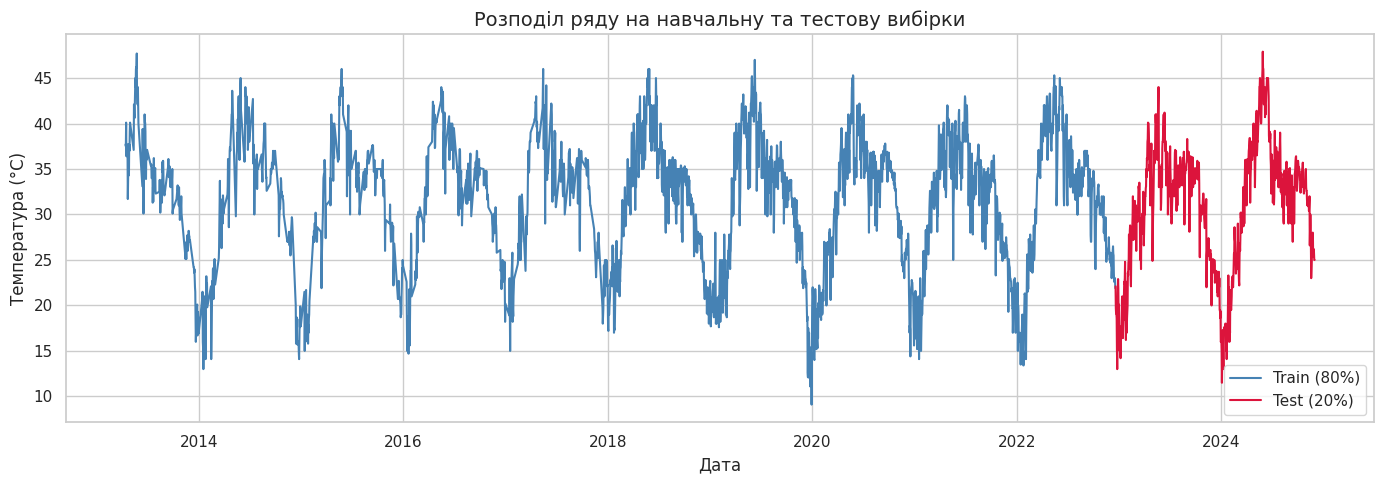

In [15]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
y_series = df[temp_col].dropna()
train_size = int(len(y_series) * 0.8)
train, test = y_series.iloc[:train_size], y_series.iloc[train_size:]
print(f"Train період: {train.index.min().strftime('%Y-%m-%d')} — {train.index.max().strftime('%Y-%m-%d')} ({len(train)} спостережень)")
print(f"Test період:  {test.index.min().strftime('%Y-%m-%d')} — {test.index.max().strftime('%Y-%m-%d')} ({len(test)} спостережень)")
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label='Train (80%)', color='steelblue')
plt.plot(test.index, test, label='Test (20%)', color='crimson')
plt.title('Розподіл ряду на навчальну та тестову вибірки', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [17]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
from statsmodels.tsa.arima.model import ARIMA
arima_order = (1, 1, 1)
arima_model = ARIMA(train.values, order=arima_order)
arima_results = arima_model.fit()
forecast_values = arima_results.forecast(steps=len(test))
arima_forecast = pd.Series(forecast_values, index=test.index)

In [18]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_results.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -6185.431
Date:                Fri, 23 Oct 2026   AIC                          12376.863
Time:                        06:11:10   BIC                          12394.722
Sample:                             0   HQIC                         12383.304
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9549      0.006    162.289      0.000       0.943       0.966
ma.L1         -1.0000      0.060    -16.567      0.000      -1.118      -0.882
sigma2         4.5289      0.264     17.185      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

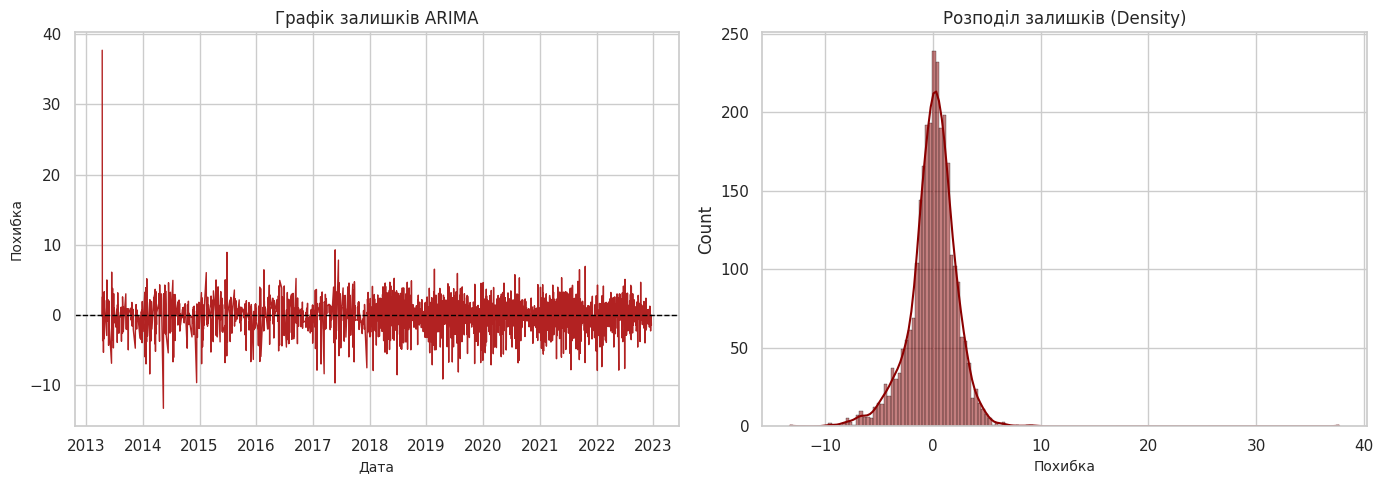

Середнє значення залишків: -0.0139
Дисперсія залишків (sigma^2): 5.0357


In [19]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = pd.Series(arima_results.resid, index=train.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(residuals, color='firebrick', lw=1)
axes[0].axhline(0, color='black', linestyle='--', lw=1)
axes[0].set_title('Графік залишків ARIMA', fontsize=12)
axes[0].set_xlabel('Дата', fontsize=10)
axes[0].set_ylabel('Похибка', fontsize=10)
sns.histplot(residuals, kde=True, ax=axes[1], color='darkred', edgecolor='black')
axes[1].set_title('Розподіл залишків (Density)', fontsize=12)
axes[1].set_xlabel('Похибка', fontsize=10)
plt.tight_layout()
plt.show()
print(f"Середнє значення залишків: {residuals.mean():.4f}")
print(f"Дисперсія залишків (sigma^2): {residuals.var():.4f}")

In [20]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100
mae_arima = mean_absolute_error(test, arima_forecast)
rmse_arima = np.sqrt(mean_squared_error(test, arima_forecast))
mape_arima = calculate_mape(test, arima_forecast)
model_metrics = {
    'ARIMA': {
        'MAE': mae_arima,
        'RMSE': rmse_arima,
        'MAPE (%)': mape_arima
    }
}
print(f"ARIMA MAE:  {mae_arima:.4f}")
print(f"ARIMA RMSE: {rmse_arima:.4f}")
print(f"ARIMA MAPE: {mape_arima:.2f}%")

ARIMA MAE:  5.2134
ARIMA RMSE: 6.5645
ARIMA MAPE: 19.94%


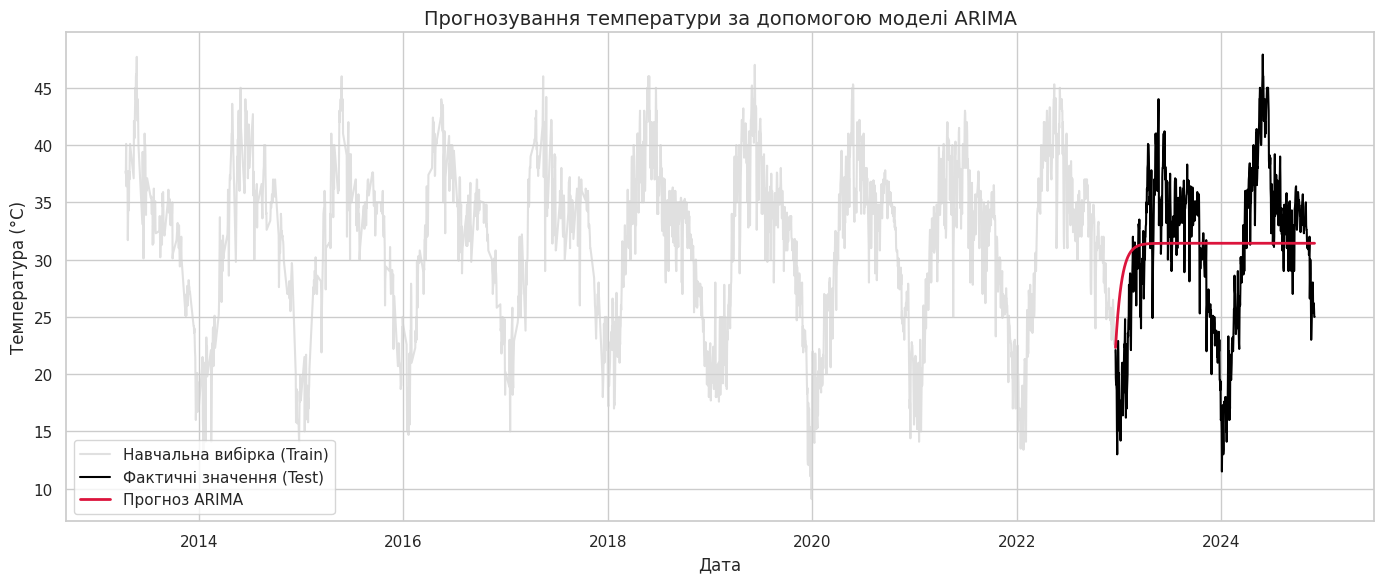

In [21]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label='Навчальна вибірка (Train)', color='lightgray', alpha=0.7)
plt.plot(test.index, test, label='Фактичні значення (Test)', color='black', lw=1.5)
plt.plot(arima_forecast.index, arima_forecast, label='Прогноз ARIMA', color='crimson', lw=2)
plt.title('Прогнозування температури за допомогою моделі ARIMA', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [22]:
# Підготуйте дані у форматі, необхідному для Prophet
train_prophet = pd.DataFrame({
    'ds': train.index,
    'y': train.values
})
display(train_prophet.head())

,ds,y
0,2013-04-14,37.7
1,2013-04-15,37.5
2,2013-04-16,40.1
3,2013-04-17,36.4
4,2013-04-18,37.5


In [23]:
# Створіть та навчіть модель Prophet
from prophet import Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
prophet_model.fit(train_prophet)

Прогноз

In [24]:
# Побудуйте прогноз Prophet для тестового періоду
future_test = pd.DataFrame({'ds': test.index})
forecast_prophet_df = prophet_model.predict(future_test)
prophet_forecast = pd.Series(forecast_prophet_df['yhat'].values, index=test.index)
display(forecast_prophet_df[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].head())

,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,20.362883,16.933739,24.286008
1,2022-12-21,20.154605,16.604680,23.731236
2,2022-12-22,19.937714,16.579246,22.969551
3,2022-12-23,19.750789,16.233359,23.069472
4,2022-12-24,19.541161,16.207264,22.996385


In [25]:
# Обчисліть MAE, RMSE, MAPE для Prophet
mae_prophet = mean_absolute_error(test, prophet_forecast)
rmse_prophet = np.sqrt(mean_squared_error(test, prophet_forecast))
mape_prophet = calculate_mape(test, prophet_forecast)
model_metrics['Prophet'] = {
    'MAE': mae_prophet,
    'RMSE': rmse_prophet,
    'MAPE (%)': mape_prophet
}
print(f"Prophet MAE:  {mae_prophet:.4f}")
print(f"Prophet RMSE: {rmse_prophet:.4f}")
print(f"Prophet MAPE: {mape_prophet:.2f}%")

Prophet MAE:  2.3378
Prophet RMSE: 3.0343
Prophet MAPE: 8.28%


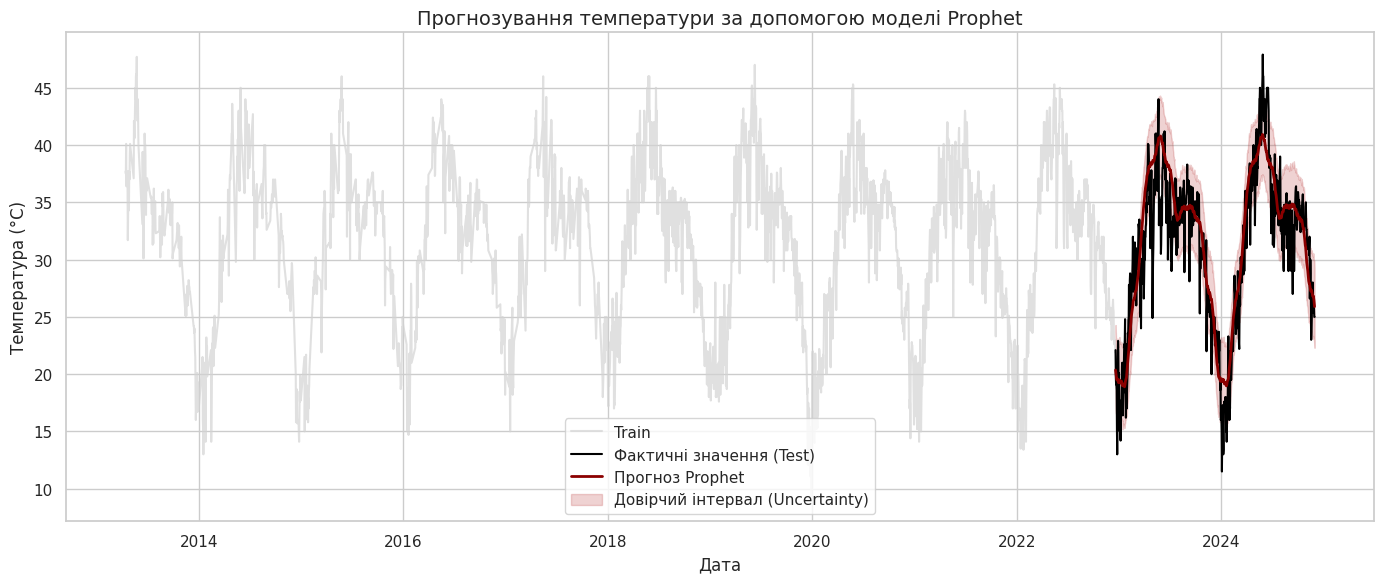

In [26]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label='Train', color='lightgray', alpha=0.7)
plt.plot(test.index, test, label='Фактичні значення (Test)', color='black', lw=1.5)
plt.plot(prophet_forecast.index, prophet_forecast, label='Прогноз Prophet', color='darkred', lw=2)
plt.fill_between(
    test.index,
    forecast_prophet_df['yhat_lower'],
    forecast_prophet_df['yhat_upper'],
    color='firebrick',
    alpha=0.2,
    label='Довірчий інтервал (Uncertainty)'
)
plt.title('Прогнозування температури за допомогою моделі Prophet', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

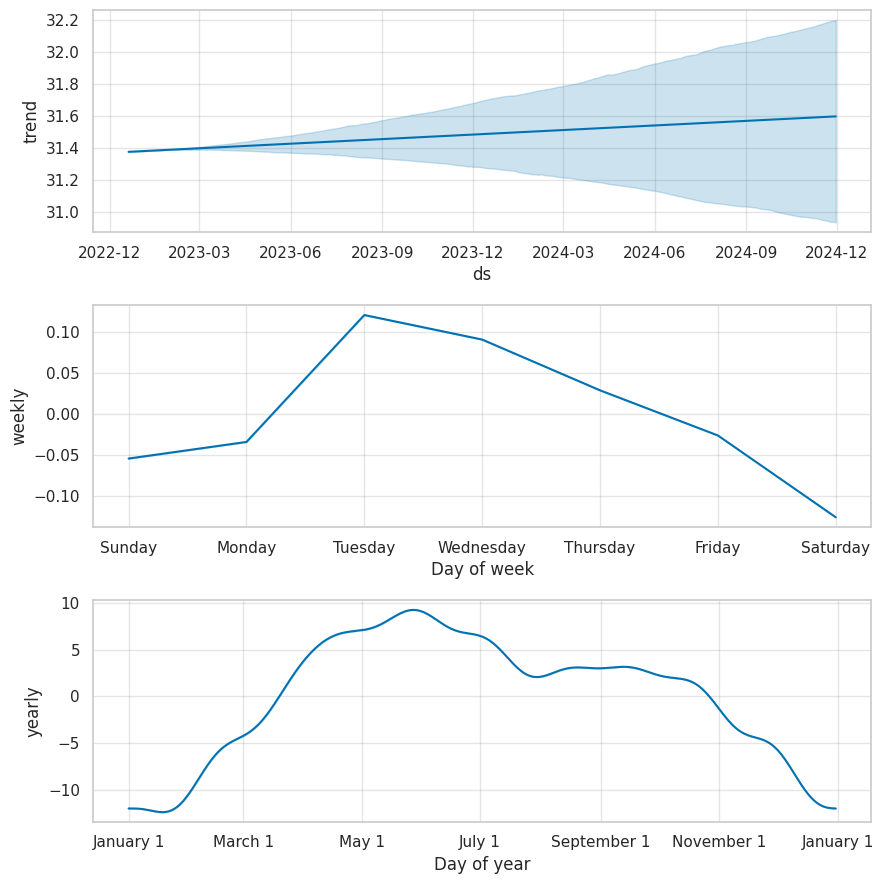

In [27]:
# Побудуйте компоненти моделі Prophet
fig_comp = prophet_model.plot_components(forecast_prophet_df)
plt.tight_layout()
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [28]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(train.values.reshape(-1, 1))
scaled_test = scaler.transform(test.values.reshape(-1, 1))
scaled_full = np.vstack((scaled_train, scaled_test))
def create_sequences(data, n_steps=30):
    X, y = [], []
    for i in range(len(data) - n_steps):
        X.append(data[i:i + n_steps])
        y.append(data[i + n_steps])
    return np.array(X), np.array(y)
n_steps = 30

In [29]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
X_train_lstm, y_train_lstm = create_sequences(scaled_train, n_steps=n_steps)
test_inputs = np.vstack((scaled_train[-n_steps:], scaled_test))
X_test_lstm, y_test_lstm = create_sequences(test_inputs, n_steps=n_steps)
print(f"X_train_lstm shape: {X_train_lstm.shape}, y_train_lstm shape: {y_train_lstm.shape}")
print(f"X_test_lstm shape:  {X_test_lstm.shape}, y_test_lstm shape:  {y_test_lstm.shape}")

X_train_lstm shape: (2815, 30, 1), y_train_lstm shape: (2815, 1)
X_test_lstm shape:  (712, 30, 1), y_test_lstm shape:  (712, 1)


In [30]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
tf.random.set_seed(42)
lstm_model = Sequential([
    LSTM(64, activation='relu', return_sequences=True, input_shape=(n_steps, 1)),
    Dropout(0.2),
    LSTM(32, activation='relu'),
    Dropout(0.2),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [31]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=40,
    batch_size=32,
    validation_split=0.1,
    verbose=1,
    shuffle=False
)

Epoch 1/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - loss: 0.0560 - val_loss: 0.0180
Epoch 2/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0162 - val_loss: 0.0098
Epoch 3/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0139 - val_loss: 0.0061
Epoch 4/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0130 - val_loss: 0.0065
Epoch 5/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.0128 - val_loss: 0.0060
Epoch 6/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0126 - val_loss: 0.0065
Epoch 7/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0111 - val_loss: 0.0066
Epoch 8/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0113 - val_loss: 0.0055
Epoch 9/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0110 - val_loss: 0.0061
Epoch 10/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 0.0107 - val_loss: 0.0066
Epoch 11/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 0.0104 - val_loss: 0.0064
Epoch 12/40
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0

In [32]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,037 (343.90 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 58,692 (229.27 KB)

In [33]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
scaled_predictions = lstm_model.predict(X_test_lstm)
lstm_forecast_raw = scaler.inverse_transform(scaled_predictions).flatten()

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step


In [34]:
# Сформуйте часові мітки для тестового прогнозу LSTM
lstm_forecast = pd.Series(lstm_forecast_raw, index=test.index)
display(lstm_forecast.head())

,0
DATE,
2022-12-20,22.444317
2022-12-21,22.135221
2022-12-22,21.541225
2022-12-23,20.948225
2022-12-24,20.466530


In [35]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm = mean_absolute_error(test, lstm_forecast)
rmse_lstm = np.sqrt(mean_squared_error(test, lstm_forecast))
mape_lstm = calculate_mape(test, lstm_forecast)
model_metrics['LSTM'] = {
    'MAE': mae_lstm,
    'RMSE': rmse_lstm,
    'MAPE (%)': mape_lstm
}
print(f"LSTM MAE:  {mae_lstm:.4f}")
print(f"LSTM RMSE: {rmse_lstm:.4f}")
print(f"LSTM MAPE: {mape_lstm:.2f}%")

LSTM MAE:  2.0266
LSTM RMSE: 2.5456
LSTM MAPE: 6.93%


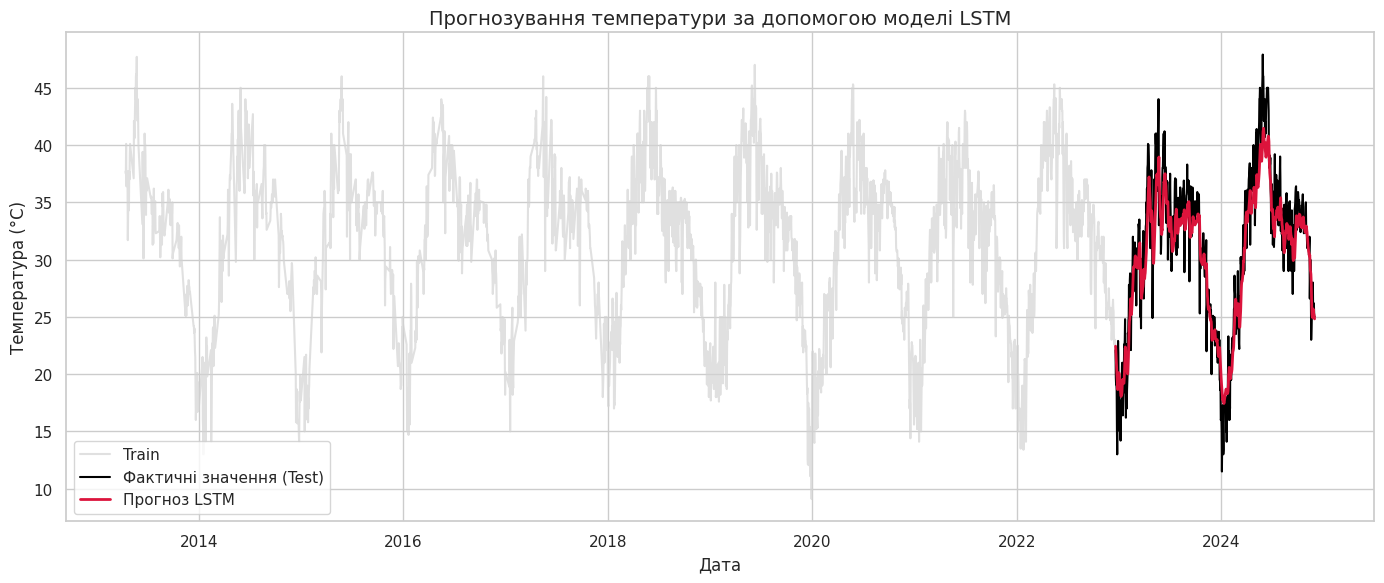

In [36]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 6))
plt.plot(train.index, train, label='Train', color='lightgray', alpha=0.7)
plt.plot(test.index, test, label='Фактичні значення (Test)', color='black', lw=1.5)
plt.plot(lstm_forecast.index, lstm_forecast, label='Прогноз LSTM', color='crimson', lw=2)
plt.title('Прогнозування температури за допомогою моделі LSTM', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Порівняння моделей

--- Підсумкова таблиця метрик якості моделей ---


,MAE,RMSE,MAPE (%)
LSTM,2.0266,2.5456,6.9295
Prophet,2.3378,3.0343,8.2814
ARIMA,5.2134,6.5645,19.9375


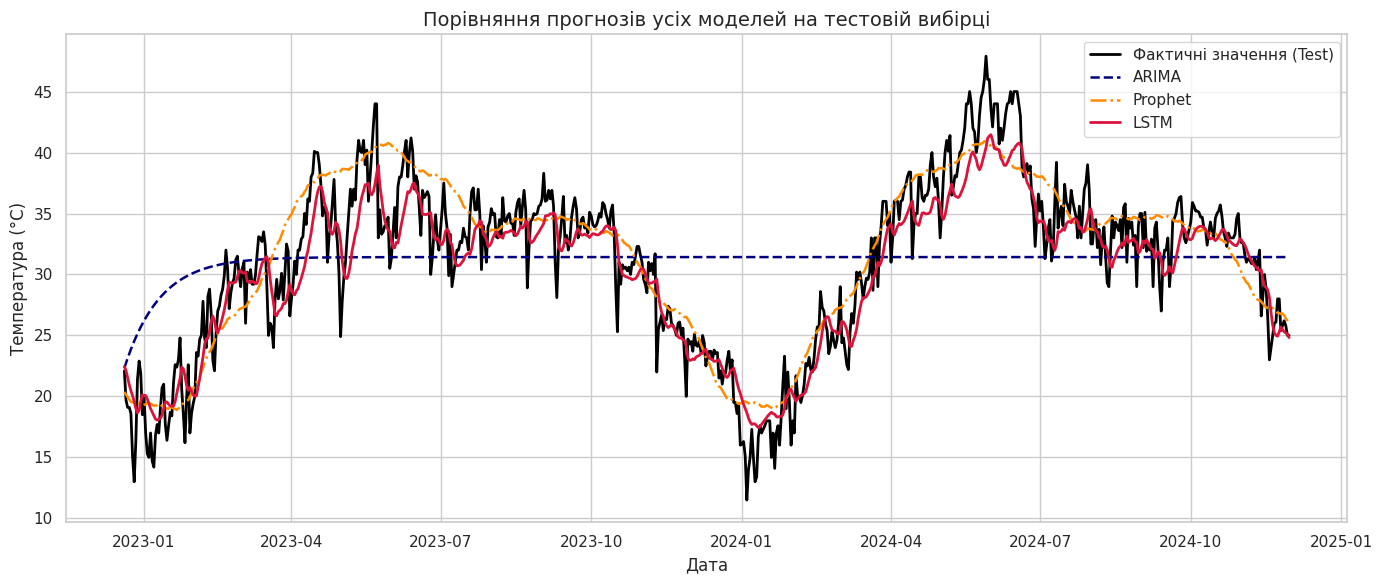

In [37]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
df_comparison = pd.DataFrame(model_metrics).T
df_comparison = df_comparison.sort_values(by='RMSE', ascending=True)
print("--- Підсумкова таблиця метрик якості моделей ---")
display(df_comparison.round(4))
plt.figure(figsize=(14, 6))
plt.plot(test.index, test, label='Фактичні значення (Test)', color='black', lw=2)
plt.plot(arima_forecast.index, arima_forecast, label='ARIMA', linestyle='--', lw=1.8, color='navy')
plt.plot(prophet_forecast.index, prophet_forecast, label='Prophet', linestyle='-.', lw=1.8, color='darkorange')
plt.plot(lstm_forecast.index, lstm_forecast, label='LSTM', lw=2, color='crimson')
plt.title('Порівняння прогнозів усіх моделей на тестовій вибірці', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


У ході лабораторної роботи проведено дослідження та побудову прогнозів для часового ряду температури за допомогою трьох підходів: класичного статистичного (**ARIMA**), адаптивного декомпозиційного (**Prophet**) та глибокого навчання (**LSTM**). Оцінювання здійснювалося на тестовій вибірці (2023–2024 роки) за метриками **MAE**, **RMSE** та **MAPE**.

**Порівняння моделей за числовими метриками:**

* **LSTM** продемонструвала найкращу точність за всіма трьома показниками: $\text{MAE} \approx 2.03^\circ\text{C}$, $\text{RMSE} \approx 2.55^\circ\text{C}$, а відносна похибка $\text{MAPE} \approx 6.93\%$.

* **Prophet** посів друге місце з незначним відставанням: $\text{MAE} \approx 2.34^\circ\text{C}$, $\text{RMSE} \approx 3.03^\circ\text{C}$ та $\text{MAPE} \approx 8.28\%$.

* **ARIMA** виявилася найменш ефективною з суттєво гіршими результатами: $\text{MAE} \approx 5.21^\circ\text{C}$, $\text{RMSE} \approx 6.56^\circ\text{C}$ і $\text{MAPE} \approx 19.94\%$.

**Аналіз поведінки моделей на графіку:**

* **LSTM (червона лінія):** найбільш точно відтворює як глобальну річну сезонність (хвилі літа й зими), так і короткострокові коливання та амплітуду пікових значень температури.

* **Prophet (помаранчевий пунктир):** формує гладку періодичну криву річного тренду; хоча модель добре схоплює загальну сезонність, вона не встигає за локальними щоденними стрибками температури.

* **ARIMA (синій пунктир):** повністю провалює довгостроковий прогноз. Після перших кількох тижнів графік вироджується у горизонтальну асимптотичну лінію на рівні $\approx 31.5^\circ\text{C}$, що підтверджує непридатність базової моделі ARIMA для моделювання складних річних сезонних циклів без урахування сезонних параметрів SARIMA.

* **Підсумок:** беззаперечним лідером за якістю прогнозування є **нейронна мережа LSTM**, яка показала найнижчі похибки та найкращу здатність повторювати реальну динаміку кліматичних показників.